# Altitude control — PPO, DQN, and SAC

This notebook uses `rnn_z` and the z-only environment. All algorithms load
settings from `src/policy/config/`; PPO and SAC use the shared training functions.
PPO supports `CurriculumCallback`; DQN uses the fixed mission. SAC starts from
the successful `ztol02` checkpoint configured in `sac.json` and uses its original
4 environments and update schedule. The 500,000-step target includes its
327,680 existing steps. Set `initial_checkpoint` to `null` for independent SAC
training from scratch.

The mission holds 0 m until 2 s, climbs to 2 m until 6 s, then lands.
The policy observes only `[z-z_ref, vz, az]` at the current time.
`ref_mission` below is the fixed mission used for evaluation and MATLAB export.

To replay the configured policy, run Setup, Load the RNN, Choose a mission,
Plot helpers, then the desired Results cell. Training cells are optional.
`SKIP_DQN` and `SKIP_SAC` control both training and results during Run All.
TensorBoard logs are saved under each algorithm's `tensorboard` folder.


## Setup


In [ ]:
# Run once if needed, then restart the kernel:
# %pip install gymnasium stable-baselines3 numpy matplotlib scipy

import json
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import gymnasium as gym
from stable_baselines3 import PPO, DQN, SAC
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.results_plotter import load_results

PROJECT_ROOT = next(
    (candidate for directory in (Path.cwd(), *Path.cwd().parents)
     for candidate in (directory, directory / "EI-DATA-DRIVEN-CONTROL")
     if (candidate / "src/model/rnn_loader.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from this project or src/policy/notebooks/ to find src/model/rnn_loader.py")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from policy.lib.droneEnv import DroneEnv, PARAMS, Z_LAND, default_mission, run_episode, evaluate
from model.rnn_loader import load_rnn_model
from policy.evaluation import training_step_offset
from policy.training import (
    CurriculumCallback, configured_checkpoint, load_ppo_config,
    train_off_policy, train_ppo,
)

from stable_baselines3.common.callbacks import EvalCallback

PPO_CONFIG_PATH = PROJECT_ROOT / "src/policy/config/ppo.json"
PPO_CONFIG = load_ppo_config(PPO_CONFIG_PATH)
DQN_CONFIG = json.loads(PPO_CONFIG_PATH.with_name("dqn.json").read_text())
SAC_CONFIG = json.loads(PPO_CONFIG_PATH.with_name("sac.json").read_text())
SEED = PPO_CONFIG["seed"]
# Starting height index for z-only PPO; SAC uses its JSON curriculum setting.
CURRICULUM_DIFFICULTY = 0
# Skip both training and results for these algorithms during Run All.
SKIP_DQN = False
SKIP_SAC = False
torch.set_num_threads(1)
# Saved results: edit one path to inspect a different checkpoint.
MODEL_PATH = PROJECT_ROOT / "src" / "policy" / "checkpoints" / "ppo_drone_rnn.zip"
PPO_MODEL_PATH = MODEL_PATH
DQN_MODEL_PATH = PROJECT_ROOT / 'src/policy/logs/tuning_dqn_multistep_20261103_163054/best_model.zip'
SAC_MODEL_PATH = (configured_checkpoint(SAC_CONFIG) or configured_checkpoint(SAC_CONFIG, "initial_checkpoint"))

# New training runs get separate folders; plotting does not create or require them.
RUN_DIR = PROJECT_ROOT / "results" / "policy" / f"rl_z_curriculum_{time.strftime('%Y%m%d_%H%M%S')}"
LOG_DIR = RUN_DIR / "matlab"
PPO_DIR = RUN_DIR / "ppo"
PPO_STEPS = PPO_CONFIG["total_timesteps"]
PPO_PARAMS = dict(PPO_CONFIG["ppo"])
PPO_INITIAL_LOG_STD = PPO_CONFIG["initial_log_std"]
DQN_DIR = RUN_DIR / "dqn"
DQN_STEPS = DQN_CONFIG["total_timesteps"]
DQN_PARAMS = dict(DQN_CONFIG["dqn"])
SAC_DIR = RUN_DIR / "sac"
SAC_STEPS = SAC_CONFIG["total_timesteps"]
SAC_PARAMS = dict(SAC_CONFIG["sac"])


## Load the altitude RNN

Load `src/model/checkpoints/rnn_z` with its single linear output head.
The model predicts vertical acceleration from one collective motor command.
Each environment keeps its own recurrent hidden state.


In [2]:
model_path = PROJECT_ROOT / "src" / "model" / "checkpoints" / "rnn_z"
acceleration_rnn = load_rnn_model(model_path)

print("Model:", model_path)
print("Load: all checkpoint weights matched")
print("RNN:", acceleration_rnn.rnn)
print("Head:", acceleration_rnn.head)


Model: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/src/model/checkpoints/rnn_z
Load: all checkpoint weights matched
RNN: RNN(1, 32, batch_first=True)
Head: Linear(in_features=32, out_features=1, bias=True)


## Choose an evaluation mission

Edit `ref_mission(t)` to change evaluation, plots, and MATLAB export.
Curriculum training keeps the same timing and sets the hover height from
`[0.5, 1, 2, 5, 10]`. Set `CURRICULUM_DIFFICULTY=None` in Setup to train
on this fixed mission instead.

The policy receives only the current altitude error, vertical velocity,
and acceleration. It cannot see the mission schedule or future references.


In [3]:
def ref_mission(t):
    """Hold 0 m until 2 s, hover at 2 m until 6 s, then land."""
    return 0.0 if t < 2.0 else (2.0 if t < 6.0 else Z_LAND)


## Plot helpers

Shared action wrappers and plotting functions; this cell does not train or load a policy.


In [4]:
DQN_COMMANDS = np.linspace(
    DQN_CONFIG["action_grid"]["low"], DQN_CONFIG["action_grid"]["high"],
    DQN_CONFIG["action_grid"]["count"], dtype=np.float32,
)

class DiscreteDroneActions(gym.ActionWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.action_space = gym.spaces.Discrete(len(DQN_COMMANDS))

    def action(self, index):
        return np.array([DQN_COMMANDS[int(index)]], dtype=np.float32)

def show_result(name, checkpoint, mission_to_test = None):
    if callable(checkpoint):
        learned_policy = checkpoint
        model = None
        checkpoint = None
    else:
        checkpoint = Path(checkpoint)
        load_kwargs = {"replay_buffer_class": None} if name == "DQN" else {}
        model = {"PPO": PPO, "DQN": DQN, "SAC": SAC}[name].load(checkpoint, device="cpu", **load_kwargs)
        commands = np.load(checkpoint.parent / "commands.npy") if name == "DQN" else None

        def learned_policy(obs):
            action = model.predict(obs, deterministic=True)[0]
            return np.array([commands[int(action)]], dtype=np.float32) if commands is not None else action

    if mission_to_test is not None:
        eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=mission_to_test)
    else:
        eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
    if model is not None:
        print(f"{name}: {checkpoint} ({model.num_timesteps:,} training steps)")
    else:
        print(f"{name}: heuristic controller")
    states, actions, total, outcome = run_episode(eval_env, learned_policy, seed=100)
    base = eval_env.unwrapped
    mission = base.mission
    t = np.arange(len(states)) * base.p.dt
    u = np.asarray(actions).reshape(len(actions), -1)
    targets = np.asarray([mission(float(ti)) for ti in t])
    z_target = targets if targets.ndim == 1 else targets[:, 0]
    has_psi = states.shape[1] > 11
    mae = np.mean(np.abs(states[1:, 0] - z_target[1:]))
    rms_du = np.sqrt(np.mean(np.diff(np.vstack([np.zeros((1, u.shape[1])), u]), axis=0) ** 2))
    status = ", ".join(outcome) if isinstance(outcome, tuple) else outcome
    print(f"{name}: {status} at {t[-1]:.2f} s | return {total:.1f} | "
          f"MAE {mae:.3f} m | peak altitude {states[:, 0].max():.3f} m | "
          f"final vz {states[-1, 1]:.3f} m/s | RMS delta-u {rms_du:.3f}")
    if has_psi:
        print(f"Final psi: {states[-1, 11]:.3f} rad ({np.degrees(states[-1, 11]):.1f} deg)")
        print(f"Final pitch/roll: {np.degrees(states[-1, 9]):.1f} / "
              f"{np.degrees(states[-1, 10]):.1f} deg | "
              f"angular speed {np.linalg.norm(states[-1, [12, 14, 16]]):.3f} rad/s")
    horizon = base.max_steps * base.p.dt
    duration = t[-1]
    end = min(horizon, duration + 0.25) if duration < 2.0 else horizon
    fig, axes = plt.subplots(6 if has_psi else 3, 1,
                             figsize=(9, 12 if has_psi else 7), sharex=True)
    mask = t <= end
    line, = axes[0].plot(t[mask], states[mask, 0], label=f"{name}: {status} at {t[-1]:.2f} s")
    color = line.get_color()
    axes[1].plot(t[mask], states[mask, 1], color=color)
    final_values = [states[-1, 0], states[-1, 1]]
    ylabels = ["Altitude z (m)", "Velocity vz (m/s)"]
    if has_psi:
        # Physical angles from the environment; yaw keeps complete turns visible.
        angle_specs = [(11, "psi", "Yaw psi (rad)"),
                       (9, "theta", "Pitch theta (rad; uncontrolled)"),
                       (10, "phi", "Roll phi (rad)")]
        for ax, (index, angle, ylabel) in zip(axes[2:5], angle_specs):
            ax.plot(t[mask], states[mask, index], color=color, label=f"Environment {angle}")
            final_values.append(states[-1, index])
            ylabels.append(ylabel)
    padded_u = np.vstack([u, u[-1:]])
    command_labels = ["u_base", "u_diff"] if u.shape[1] == 2 else [f"u{i + 1}" for i in range(u.shape[1])]
    for channel, label in enumerate(command_labels):
        command_line, = axes[-1].step(t[mask], padded_u[mask, channel],
                                      where="post", label=label)
        if t[-1] <= end:
            axes[-1].plot(t[-1], u[-1, channel], "x", color=command_line.get_color())
    if u.shape[1] > 1:
        axes[-1].legend(fontsize=8)
    if t[-1] <= end:
        for ax, value in zip(axes[:-1], final_values):
            ax.plot(t[-1], value, "x", color=color)
        for ax in axes:
            ax.axvline(t[-1], color=color, linestyle=":", alpha=0.4)
    reference_t = np.arange(0, end + base.p.dt / 2, base.p.dt)
    reference = np.asarray([mission(float(ti)) for ti in reference_t])
    z_reference = reference if reference.ndim == 1 else reference[:, 0]
    axes[0].step(reference_t, z_reference, where="post",
                 color="black", linestyle="--", label="Mission target")
    if has_psi:
        # Rotation missions use (z, phi, psi); pitch is plotted without a target.
        # Legacy (z, psi) and (z, theta, phi, psi) missions are also accepted.
        # theta_reference = np.zeros_like(reference_t)
        phi_reference = np.zeros_like(reference_t)
        psi_reference = np.zeros_like(reference_t)
        if reference.ndim == 2:
            psi_reference = reference[:, -1]
            if reference.shape[1] == 3:
                phi_reference = reference[:, 1]
            elif reference.shape[1] == 4:
                # theta_reference = reference[:, 1]
                phi_reference = reference[:, 2]
        for ax, target, angle in zip([axes[2], axes[4]],
                                     [psi_reference, phi_reference],
                                     ["psi", "phi"]):
            ax.plot(reference_t, target, color="black", linestyle="--",
                    label=f"Mission {angle} target")
            ax.legend(fontsize=8)
    ylabels.append("Command u")
    for ax, ylabel in zip(axes, ylabels):
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
    axes[0].set_title(f"{name} — saved policy" if model is not None else name)
    axes[0].legend(fontsize=8)
    axes[-1].set(xlabel="Time (s)", xlim=(0, end))
    fig.tight_layout()
    plt.show()
    eval_env.close()

    if checkpoint is not None and list(checkpoint.parent.glob("*.monitor.csv")):
        history = load_results(str(checkpoint.parent))
        returns = history["r"].to_numpy()
        steps = history["l"].cumsum().to_numpy() + training_step_offset(checkpoint.parent)
        window = min(20, len(returns))
        fig, ax = plt.subplots(figsize=(9, 3))
        if window:
            ax.plot(steps[window - 1:], np.convolve(returns, np.ones(window) / window, "valid"),
                    label=f"Training: mean over {window} episodes", alpha=0.7)
        evaluation_file = checkpoint.parent / "evaluations.npz"
        if evaluation_file.is_file():
            with np.load(evaluation_file) as evaluations:
                ax.plot(evaluations["timesteps"], evaluations["results"].mean(axis=1),
                        marker=".", label="Deterministic evaluation")
        ax.axvline(model.num_timesteps, color="black", linestyle=":", label="Loaded checkpoint")
        ax.set(title=f"{name} learning curve", xlabel="Environment steps", ylabel="Episode return")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
        fig.tight_layout()
        plt.show()

## Optional environment check


In [5]:
env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
check_env(env)
obs, info = env.reset(seed=SEED)
print("Observation:", obs, env.observation_space)
print("Action:", env.action_space)
print("check_env: OK")
env.close()


Observation: [ 0.     0.    -9.816] Box([ -inf  -20. -100.], [ inf  20. 100.], (3,), float32)
Action: Box(-3.0, 3.0, (1,), float32)
check_env: OK


/home/rayan768/venvs/main_env/lib/python3.13/site-packages/stable_baselines3/common/env_checker.py:515: UserWarning: We recommend you to use a symmetric and normalized Box action space (range=[-1, 1]) cf. https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html
  warnings.warn(


## PPO — optional training

Settings come from `src/policy/config/ppo.json`. This cell uses the same
training function as `main_z.py` and saves TensorBoard logs and the resolved
config under `PPO_DIR`.

Curriculum training is enabled by default.
`CURRICULUM_DIFFICULTY` is the starting index in `[0.5, 1, 2, 5, 10]`;
set it to `None` for the fixed mission. The callback advances modulo 5 after
at least 85% success over 20 completed episodes at the current height.
Success means reaching the target within 0.2 m, then landing softly.
Timing stays 0 m until 2 s, hover until 6 s, then land (10 s deadline).
Difficulty changes apply at episode resets. Evaluation stays on `ref_mission`.
The final curriculum checkpoint is selected; TensorBoard logs `curriculum/*`.


In [6]:
ppo_curriculum = (
    CurriculumCallback(difficulty=CURRICULUM_DIFFICULTY, verbose=1)
    if CURRICULUM_DIFFICULTY is not None else None
)
start = time.perf_counter()
agent, PPO_MODEL_PATH = train_ppo(
    acceleration_rnn,
    ref_mission,
    PPO_DIR,
    total_timesteps=PPO_STEPS,
    seed=SEED,
    env_class=DroneEnv,
    initial_log_std=PPO_INITIAL_LOG_STD,
    config_path=PPO_CONFIG_PATH,
    curriculum=ppo_curriculum,
    **PPO_PARAMS,
)
print(f"PPO: {agent.num_timesteps:,}-step checkpoint; {time.perf_counter() - start:.1f} s")
print("Checkpoint:", PPO_MODEL_PATH)
print("TensorBoard logs:", PPO_DIR / "tensorboard")


Exported /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_curriculum_20261105_223941/ppo/policy.mat and /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_curriculum_20261105_223941/ppo/traj_model.mat (156 steps; command error 1.8e-07)
PPO: 501,760-step checkpoint; 192.4 s
Checkpoint: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_curriculum_20261105_223941/ppo/ppo_drone_rnn.zip
TensorBoard logs: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_curriculum_20261105_223941/ppo/tensorboard


## PPO — Results

Run this cell directly after the shared setup cells to load the saved PPO.


PPO: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_curriculum_20261105_223941/ppo/ppo_drone_rnn.zip (501,760 training steps)
PPO: landed at 7.80 s | return 542.7 | MAE 0.398 m | peak altitude 1.949 m | final vz -0.211 m/s | RMS delta-u 0.467


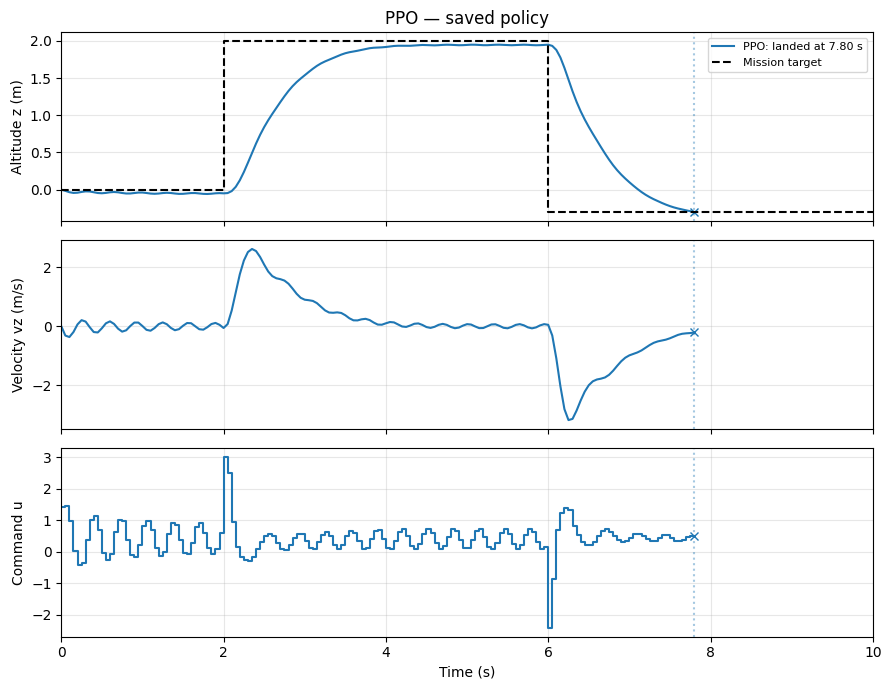

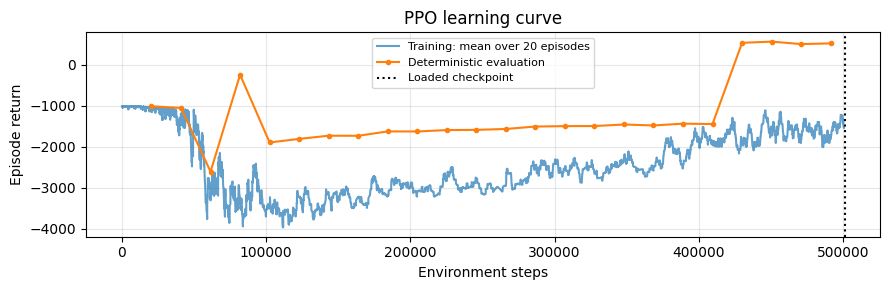

In [7]:
show_result("PPO", PPO_MODEL_PATH)


In [8]:
# train_ppo already saved the selected policy in PPO_DIR.
print("Saved policy:", PPO_MODEL_PATH)

from policy.export_policy import export_for_matlab
export_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
try:
    export_for_matlab(agent, export_env, output_dir=LOG_DIR)
finally:
    export_env.close()


Saved policy: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_curriculum_20261105_223941/ppo/ppo_drone_rnn.zip
Exported /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_curriculum_20261105_223941/matlab/policy.mat and /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_curriculum_20261105_223941/matlab/traj_model.mat (156 steps; command error 1.8e-07)


## Changing mission

In [24]:
def test_mission(t):
    """Hold 0 m until 2 s, hover at 2 m until 5 s, then land."""
    return 0.0 if t < 2.0 else (9.0 if t < 5.0 else Z_LAND)


PPO: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_curriculum_20261105_223941/ppo/ppo_drone_rnn.zip (501,760 training steps)
PPO: landed at 6.65 s | return -2035.5 | MAE 2.226 m | peak altitude 8.929 m | final vz -0.326 m/s | RMS delta-u 0.500


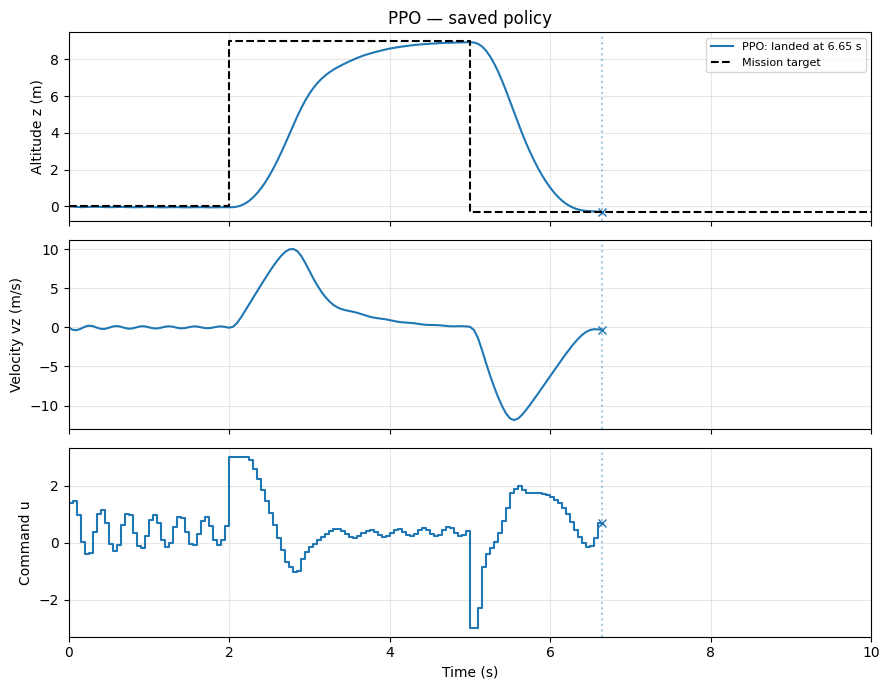

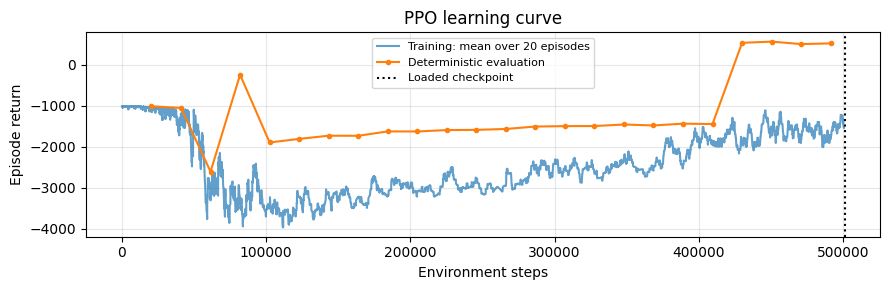

In [25]:
show_result("PPO", PPO_MODEL_PATH, mission_to_test=test_mission)

## DQN — optional training

Skipped when `SKIP_DQN=True` in Setup.

Use 61 commands evenly spaced across `[-3.0, 3.0]` (0.1 increments), covering
its full environment action range for the selected mission. Rerun this training
cell to learn with the wider command range; existing checkpoints retain their
original saved `commands.npy`. The Results cell reports peak altitude so you can
check whether the trained policy reaches its target.

Training settings and the command grid are loaded from `src/policy/config/dqn.json`.
The successful DQN settings use `n_steps=3`, `tau=0.1`, and `train_freq=5`.
With `gradient_steps=-1`, 50 transitions are followed by 50 updates with 10 environments.

Sources: [DQN parameters](https://stable-baselines3.readthedocs.io/en/master/modules/dqn.html#parameters),
[multi-environment update guidance](https://stable-baselines3.readthedocs.io/en/master/guide/examples.html#multiprocessing-with-off-policy-algorithms).


In [11]:
if SKIP_DQN:
    print("DQN skipped (SKIP_DQN=True).")
else:
    def make_dqn_env():
        env = DiscreteDroneActions(DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission))
        return env

    dqn_env = make_vec_env(make_dqn_env, n_envs=DQN_CONFIG["n_envs"], seed=DQN_CONFIG["seed"], monitor_dir=str(DQN_DIR))
    dqn_eval = make_vec_env(make_dqn_env, n_envs=1, seed=100)
    dqn_callback = EvalCallback(
        dqn_eval, best_model_save_path=str(DQN_DIR), log_path=str(DQN_DIR),
        eval_freq=max(1, DQN_CONFIG["eval_freq"] // DQN_CONFIG["n_envs"]), n_eval_episodes=1, deterministic=True, verbose=0,
    )
    dqn_agent = DQN("MlpPolicy", dqn_env, seed=DQN_CONFIG["seed"], device="cpu", verbose=0, **DQN_PARAMS)
    start = time.perf_counter()
    dqn_agent.learn(total_timesteps=DQN_STEPS, callback=dqn_callback)
    dqn_agent.save(DQN_DIR / "dqn_drone_rnn")
    np.save(DQN_DIR / "commands.npy", DQN_COMMANDS)
    DQN_MODEL_PATH = DQN_DIR / "best_model.zip"
    dqn_env.close()
    dqn_eval.close()
    print(f"DQN: {dqn_agent.num_timesteps:,} steps in {time.perf_counter() - start:.1f} s; {DQN_MODEL_PATH}")


DQN skipped (SKIP_DQN=True).


## DQN — Results

Skipped when `SKIP_DQN=True` in Setup.

Loads only DQN and its saved `commands.npy`; PPO and SAC do not need to run.


In [12]:
if SKIP_DQN:
    print("DQN skipped (SKIP_DQN=True).")
else:
    show_result("DQN", DQN_MODEL_PATH)


DQN skipped (SKIP_DQN=True).


## SAC — optional training

Skipped when `SKIP_SAC=True` in Setup.

Training uses `train_off_policy` from `policy.training`, just like `main_z.py`.
Settings and the starting checkpoint come from `src/policy/config/sac.json`.
The altitude baseline is `20261105_202000_ztol02/training/best_model.zip` at
327,680 steps. The 500,000-step target includes those existing steps.
The old zip has no replay buffer: training collects 2,000 fresh warmup
transitions before updates. The starting policy is evaluated and saved before
training, and remains selected unless a later evaluation improves its return.
Set `initial_checkpoint` to `null` in the config to train altitude SAC from scratch.

SAC uses the environment's full continuous action space and the fixed mission.
`curriculum_difficulty` optionally enables the altitude curriculum; curriculum
runs select the final checkpoint. TensorBoard logs and a resolved config are
saved under `SAC_DIR`.


In [13]:
if SKIP_SAC:
    print("SAC skipped (SKIP_SAC=True).")
else:
    sac_curriculum = (
        CurriculumCallback(difficulty=SAC_CONFIG["curriculum_difficulty"], verbose=1)
        if SAC_CONFIG["curriculum_difficulty"] is not None else None
    )
    start = time.perf_counter()
    sac_agent, SAC_MODEL_PATH = train_off_policy(
        "sac", acceleration_rnn, ref_mission, SAC_DIR,
        config_path=PPO_CONFIG_PATH.with_name("sac.json"),
        total_timesteps=SAC_STEPS, seed=SAC_CONFIG["seed"], n_envs=SAC_CONFIG["n_envs"],
        env_class=DroneEnv, curriculum=sac_curriculum,
        **SAC_PARAMS,
    )
    print(f"SAC: selected {sac_agent.num_timesteps:,}-step checkpoint in {time.perf_counter() - start:.1f} s; {SAC_MODEL_PATH}")


SAC skipped (SKIP_SAC=True).


## SAC — Results

Skipped when `SKIP_SAC=True` in Setup.

Loads only SAC; PPO and DQN do not need to run.

For altitude, Setup selects the verified SAC policy from the shared config.
Running the training cell first selects that run's best checkpoint instead.


In [14]:
if SKIP_SAC:
    print("SAC skipped (SKIP_SAC=True).")
else:
    show_result("SAC", SAC_MODEL_PATH)


SAC skipped (SKIP_SAC=True).


## Export a PPO trajectory

Exports `trajectory_az.csv` into this run's PPO directory using the same selected
mission. MATLAB policy export above also includes that mission's reference samples.


In [15]:

# 1. Déroulement d'un épisode avec la politique entraînée
eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
obs, info = eval_env.reset(seed=0)

az_list = [float(eval_env.unwrapped.state[2])]

terminated = False
truncated = False

while not (terminated or truncated):
    action, _ = agent.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = eval_env.step(action)
    az_list.append(float(eval_env.unwrapped.state[2]))

eval_env.close()

# 2. Export sur une seule ligne (chaque case = une valeur de az)
LOG_DIR.mkdir(parents=True, exist_ok=True)
output_path = LOG_DIR / "trajectory_az.csv"
np.savetxt(output_path, [az_list], delimiter=",", fmt="%.6f")

print(f"Trajectoire az exportée ({len(az_list)} valeurs sur 1 ligne) : {output_path}")

Trajectoire az exportée (157 valeurs sur 1 ligne) : /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_curriculum_20261105_223941/matlab/trajectory_az.csv
